# 01 - Encoder verification

Phase 1 check: our own `VisionTransformer`, loaded with pretrained CLIP ViT-B/16 weights, reproduces HuggingFace's `CLIPVisionModel`, and its patch tokens carry real visual structure.

1. Load both models and one real image.
2. Compare all 13 hidden states (embeddings + 12 blocks).
3. Look at the penultimate-layer patch tokens (the tensor the VLM will consume) with a PCA and a patch-similarity map.
4. Run the same weights at a higher resolution via position-embedding interpolation.

In [1]:
import os, sys, urllib.request
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from transformers import CLIPVisionModel, CLIPVisionConfig

from src.models.vit.load_pretrained import load_clip_vit, clip_transform, CLIP_MEAN, CLIP_STD

MODEL_NAME = "openai/clip-vit-base-patch16"
IMG_PATH = "../data/samples/cats.jpg"
IMG_URL = "http://images.cocodataset.org/val2017/000000039769.jpg"   # COCO val2017 sample

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8f98", "axes.labelcolor": "#4b5058", "xtick.color": "#4b5058", "ytick.color": "#4b5058",
})
os.makedirs(os.path.dirname(IMG_PATH), exist_ok=True)
os.makedirs("../docs/assets", exist_ok=True)
if not os.path.exists(IMG_PATH):
    urllib.request.urlretrieve(IMG_URL, IMG_PATH)

## 1. Load models and image

own ViT params: 85.8M, depth=12


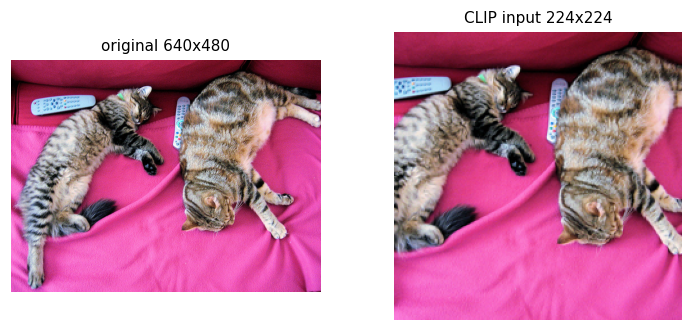

In [2]:
ours = load_clip_vit(MODEL_NAME)
hf = CLIPVisionModel.from_pretrained(MODEL_NAME, config=CLIPVisionConfig.from_pretrained(MODEL_NAME)).eval()
print(f"own ViT params: {sum(p.numel() for p in ours.parameters()) / 1e6:.1f}M, depth={ours.depth}")

image = Image.open(IMG_PATH).convert("RGB")
x = clip_transform(224)(image).unsqueeze(0)          # (1, 3, 224, 224)

def to_display(t):
    # undo CLIP normalisation for plotting
    mean = torch.tensor(CLIP_MEAN).view(3, 1, 1); std = torch.tensor(CLIP_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
ax[0].imshow(image); ax[0].set_title(f"original {image.size[0]}x{image.size[1]}", fontsize=10)
ax[1].imshow(to_display(x[0])); ax[1].set_title("CLIP input 224x224", fontsize=10)
for a in ax: a.axis("off")
plt.show()

## 2. Layer-by-layer equivalence

`hidden_states[i]` in HuggingFace is the output after `i` blocks (0 = embeddings after the pre-LayerNorm). Our `forward_features(layer=i, drop_cls=False)` uses the same indexing.

In [3]:
with torch.no_grad():
    hf_states = hf(x, output_hidden_states=True).hidden_states
    rows = []
    for i, expected in enumerate(hf_states):
        got = ours.forward_features(x, layer=i, drop_cls=False)
        rows.append((i, (got - expected).abs().max().item()))

print(f"{'layer':>5}  {'max |ours - HF|':>16}")
for i, d in rows:
    print(f"{i:>5}  {d:>16.2e}")
print("\nall within 1e-4:", all(d < 1e-4 for _, d in rows))

layer   max |ours - HF|
    0          0.00e+00
    1          0.00e+00
    2          0.00e+00
    3          0.00e+00
    4          0.00e+00
    5          0.00e+00
    6          0.00e+00
    7          0.00e+00
    8          0.00e+00
    9          0.00e+00
   10          0.00e+00
   11          0.00e+00
   12          0.00e+00

all within 1e-4: True


All-zero differences are only meaningful if the check can fail. As a control, perturb a single MLP weight in block 5 and repeat: the difference should be non-zero from layer 6 on and grow with depth.

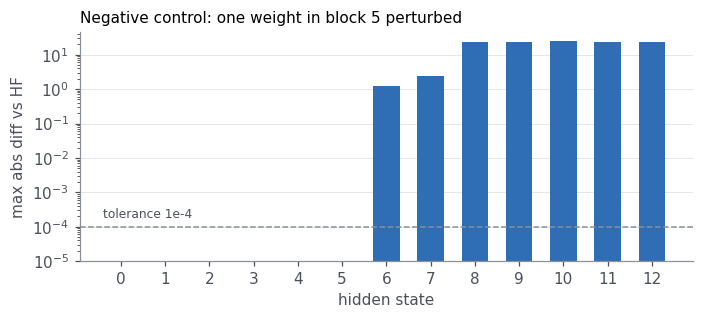

restored max diff: 0.0


In [4]:
layer_w = ours.encoder_blocks[5].mlp.net[0].weight
original = layer_w.data.clone()
try:
    layer_w.data += 1e-2
    with torch.no_grad():
        control = [(ours.forward_features(x, layer=i, drop_cls=False) - hf_states[i]).abs().max().item()
                   for i in range(len(hf_states))]
finally:
    layer_w.data.copy_(original)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(range(len(control)), control, color="#2f6db5", width=0.6)
ax.axhline(1e-4, color="#8a8f98", lw=1, ls="--")
ax.text(-0.4, 1.5e-4, "tolerance 1e-4", ha="left", va="bottom", fontsize=8, color="#4b5058")
ax.set_yscale("log"); ax.set_ylim(1e-5, None)
ax.set_xticks(range(len(control))); ax.set_xlabel("hidden state"); ax.set_ylabel("max abs diff vs HF")
ax.set_title("Negative control: one weight in block 5 perturbed", fontsize=10, loc="left")
ax.grid(axis="y", color="#e3e5e8", lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

# the restored model matches again
with torch.no_grad():
    print("restored max diff:", (ours.forward_features(x, layer=-2, drop_cls=False) - hf_states[-2]).abs().max().item())

## 3. What the VLM will consume

LLaVA-style models take the **penultimate** layer's patch tokens (CLS dropped, final LayerNorm not applied). For a 224px image with 16px patches that is a `14 x 14 = 196` token grid of 768-d vectors.

In [5]:
with torch.no_grad():
    tokens = ours.forward_features(x, layer=-2, drop_cls=True)       # (1, 196, 768)
    expected = hf_states[-2][:, 1:]
print("shape:", tuple(tokens.shape), "| max diff vs HF:", (tokens - expected).abs().max().item())
print("per-token L2 norm: mean %.1f, max %.1f" % (tokens.norm(dim=-1).mean(), tokens.norm(dim=-1).max()))

shape: (1, 196, 768) | max diff vs HF: 0.0
per-token L2 norm: mean 13.8, max 92.1


### PCA of the patch tokens

Project each token onto the top three principal components (fit on this image's tokens only) and show them as RGB on the patch grid. If the tokens encode semantics, regions of the same object should share a colour.

variance explained by top-3 PCs: ['76.1%', '6.3%', '2.9%']


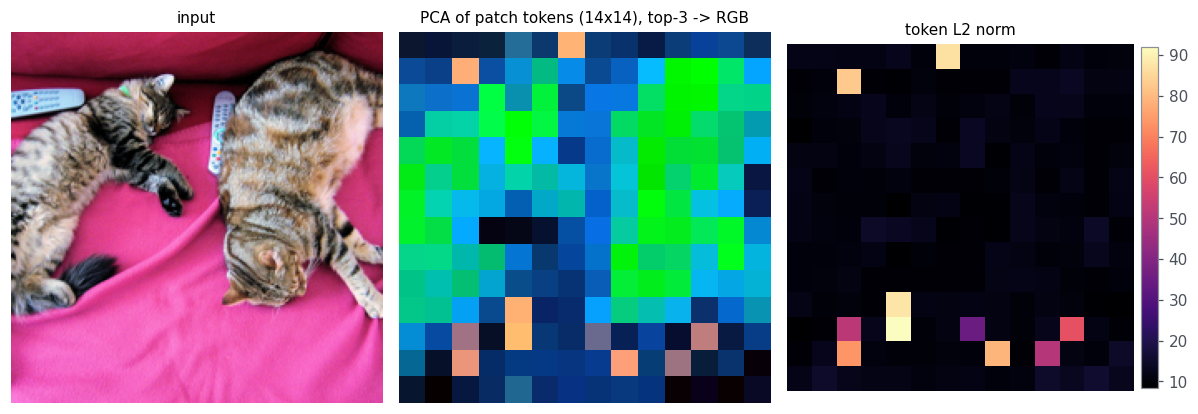

In [6]:
def pca_rgb(tokens, grid, k=3):
    t = tokens.reshape(-1, tokens.shape[-1]).float()
    t = t - t.mean(0, keepdim=True)
    U, S, Vh = torch.linalg.svd(t, full_matrices=False)
    comps = t @ Vh[:k].T                                              # (N, k)
    lo, hi = torch.quantile(comps, 0.02, dim=0), torch.quantile(comps, 0.98, dim=0)
    comps = ((comps - lo) / (hi - lo)).clamp(0, 1)
    var = (S[:k] ** 2) / (S ** 2).sum()
    return comps.reshape(grid[0], grid[1], k).numpy(), var

rgb, var = pca_rgb(tokens[0], (14, 14))
print("variance explained by top-3 PCs:", [f"{v:.1%}" for v in var.tolist()])

norms = tokens[0].norm(dim=-1).reshape(14, 14).numpy()
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(to_display(x[0])); ax[0].set_title("input", fontsize=10)
ax[1].imshow(rgb, interpolation="nearest"); ax[1].set_title("PCA of patch tokens (14x14), top-3 -> RGB", fontsize=10)
im = ax[2].imshow(norms, cmap="magma", interpolation="nearest"); ax[2].set_title("token L2 norm", fontsize=10)
fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.02)
for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("../docs/assets/pca_patch_tokens.png", bbox_inches="tight")
plt.show()

**Note: high-norm outlier tokens.** A handful of patches (the orange and pink cells above, bright in the norm map) have an L2 norm several times larger than the rest. These are a known artifact of large ViTs: the model stores global information in a few low-information background patches. They dominate the first principal component (which is why it explains most of the variance) and they are mutually similar, so a plain background patch lights up exactly those cells in the similarity map below. They are real parts of the features the LM will see, which is worth remembering when interpreting the failure analysis later.

### Patch-similarity map

Cosine similarity between one query patch and all patches. A patch on an object should light up the rest of that object.

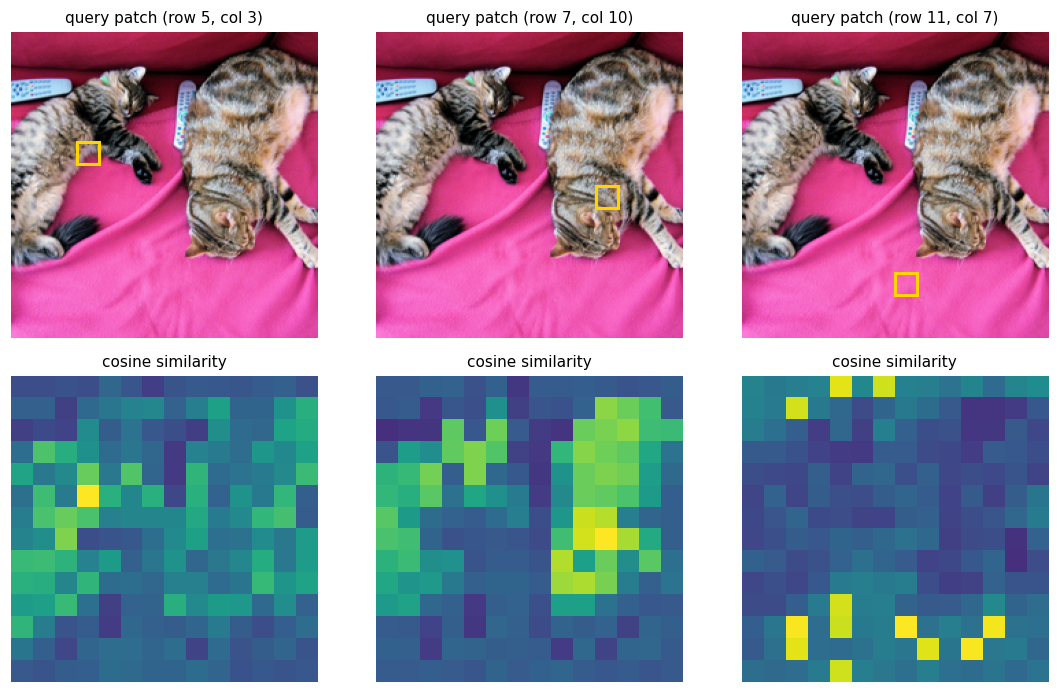

In [7]:
def similarity_map(tokens, row, col, grid=(14, 14)):
    t = F.normalize(tokens[0].float(), dim=-1)
    q = t[row * grid[1] + col]
    return (t @ q).reshape(grid).numpy()

queries = [(5, 3), (7, 10), (11, 7)]      # (row, col) on the 14x14 grid
fig, ax = plt.subplots(2, len(queries), figsize=(3.4 * len(queries), 6.4))
for j, (r, c) in enumerate(queries):
    ax[0, j].imshow(to_display(x[0]))
    ax[0, j].add_patch(plt.Rectangle((c * 16, r * 16), 16, 16, fill=False, ec="#ffd400", lw=2))
    ax[0, j].set_title(f"query patch (row {r}, col {c})", fontsize=10); ax[0, j].axis("off")
    ax[1, j].imshow(similarity_map(tokens, r, c), cmap="viridis", vmin=-0.2, vmax=1.0, interpolation="nearest")
    ax[1, j].set_title("cosine similarity", fontsize=10); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 4. Other resolutions (position-embedding interpolation)

The pretrained position embeddings are a 14x14 grid. At 336px the grid is 21x21, so they are resized bicubically. The tokens should keep their structure, though CLIP B/16 was not trained at this size, so quality can drift.

336px tokens: (1, 441, 768)


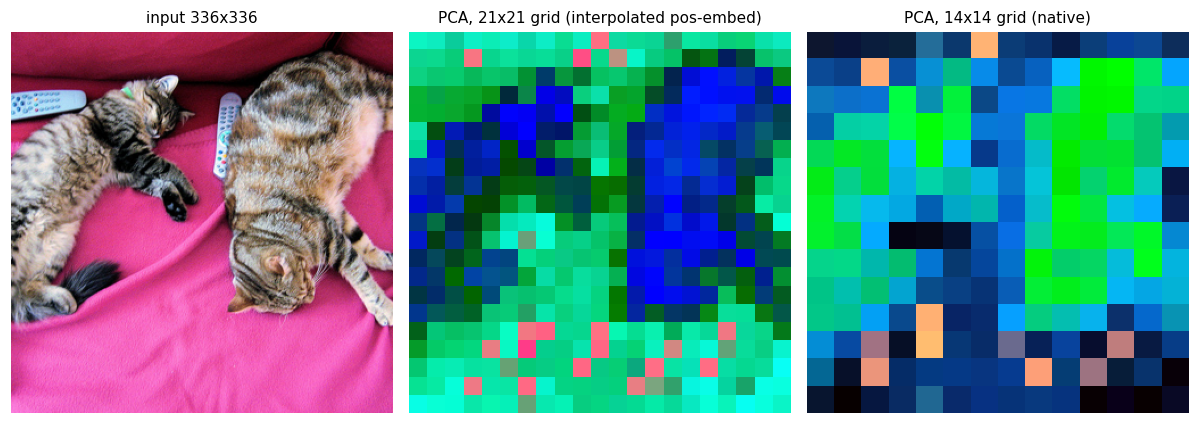

In [8]:
x336 = clip_transform(336)(image).unsqueeze(0)
with torch.no_grad():
    tokens336 = ours.forward_features(x336, layer=-2, drop_cls=True)
print("336px tokens:", tuple(tokens336.shape))

rgb336, _ = pca_rgb(tokens336[0], (21, 21))
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(to_display(x336[0])); ax[0].set_title("input 336x336", fontsize=10)
ax[1].imshow(rgb336, interpolation="nearest"); ax[1].set_title("PCA, 21x21 grid (interpolated pos-embed)", fontsize=10)
ax[2].imshow(rgb, interpolation="nearest"); ax[2].set_title("PCA, 14x14 grid (native)", fontsize=10)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## Summary

- Own ViT with CLIP weights matches HuggingFace at all 13 hidden states (tolerance 1e-4); the negative control shows the check can fail.
- The penultimate-layer patch tokens (`1 x 196 x 768`) are what Phase 2's projector will map into the LM embedding space.
- Patch tokens show clear object-level structure under PCA and similarity maps.
- Higher resolutions run through position-embedding interpolation, which later enables the visual-token-count experiments.

Automated versions of these checks live in `tests/test_vit_equivalence.py`.